In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Mounted at /content/gdrive


In [4]:
# Get name for training set
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"

# Load the data. Training set
x_train_all = np.load(f"{files_dir}/{train_diagram_name}")

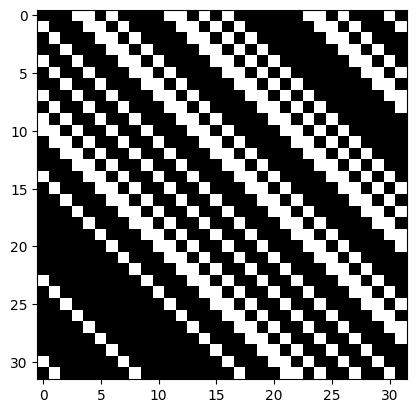

In [76]:
x_train_example = x_train_all[np.random.randint(x_train_all.shape[0]),:,:,0]
x_train_example_cropped = x_train_example[16:-16,16:-16]
plt.imshow(x_train_example_cropped, cmap='Greys')

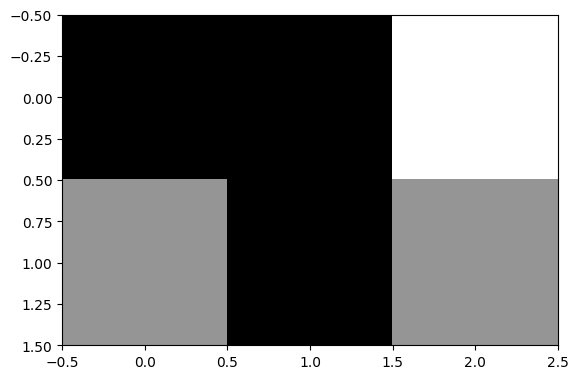

In [125]:
conv_kernel = np.array([[1,1,-1],[0,1,0]])
plt.imshow(conv_kernel, cmap='Greys')

max: 1
min: -3


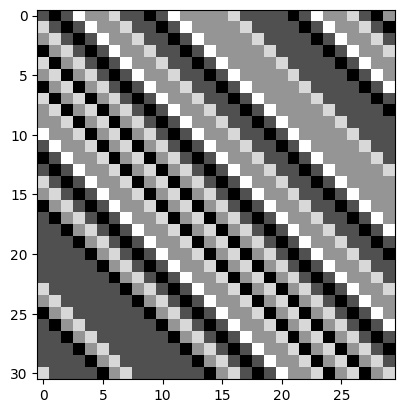

In [128]:
bias = -2

x_train_example_conv = scipy.signal.convolve2d(x_train_example_cropped, np.flip(conv_kernel), mode='valid')
x_train_example_conv += bias

print(f"max: {np.max(x_train_example_conv)}")
print(f"min: {np.min(x_train_example_conv)}")
plt.imshow(x_train_example_conv, cmap='Greys')

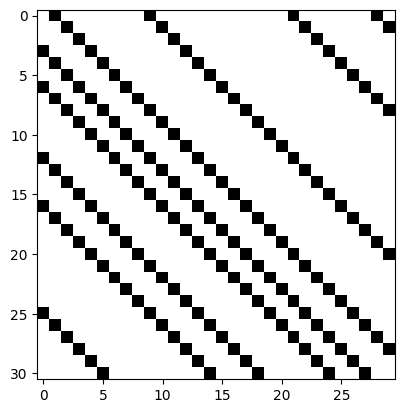

In [129]:
x_train_example_conv_relu = np.maximum(x_train_example_conv, 0)

plt.imshow(x_train_example_conv_relu, cmap='Greys')

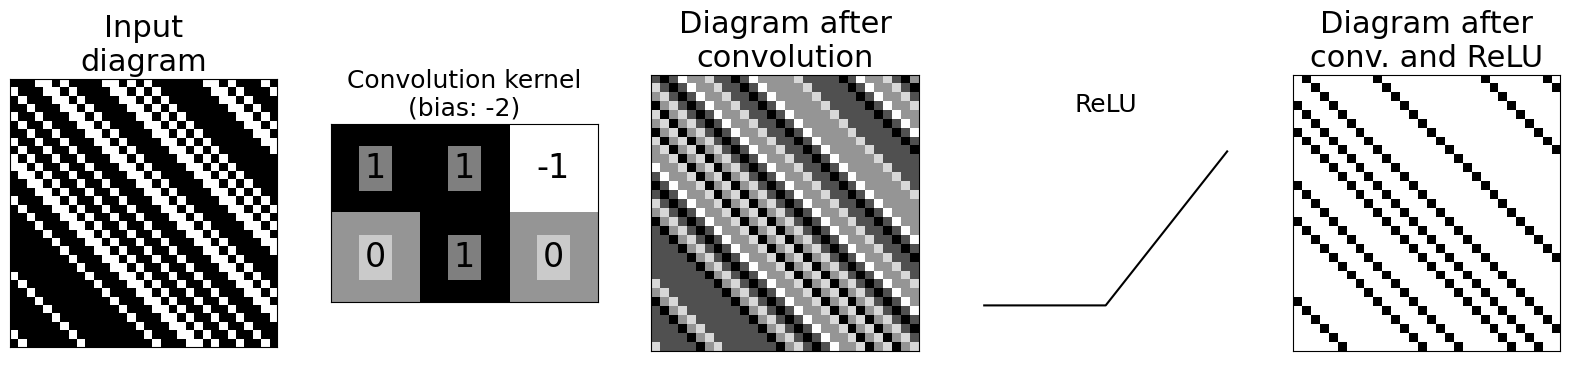

In [131]:
SAVEFIG = True

fig, axs = plt.subplots(1,5, figsize=(20,4))
fontsize = 22

axs[0].imshow(x_train_example_cropped, cmap='Greys')
axs[0].set_title("Input\ndiagram", size=fontsize)

axs[1].imshow(conv_kernel, cmap='Greys')
axs[1].set_title(f"Convolution kernel\n(bias: {bias})", size=fontsize-4)
# add labels in fancy boxes
for (j,i), label in np.ndenumerate(conv_kernel):
    txt = axs[1].text(i,j,label,ha='center', va='center', size=fontsize+2)
    txt.set_bbox(dict(facecolor='white', alpha=0.5, linewidth=0))

axs[2].imshow(x_train_example_conv, cmap='Greys')
axs[2].set_title(f"Diagram after\nconvolution", size=fontsize)

axs[3].plot(np.linspace(-1,1,101), np.array([np.maximum(i,0)-.6 for i in np.linspace(-1,1,101)]), 'k')
axs[3].set_title("ReLU", size=fontsize-4, y=.8)

axs[4].imshow(x_train_example_conv_relu, cmap='Greys')
axs[4].set_title(f"Diagram after\nconv. and ReLU", size=fontsize)

axs[3].set_ylim(-1,1)

for ax in axs:
  ax.set_xticks([])
  ax.set_yticks([])

axs[3].axis("off")

if SAVEFIG:
  savename = "example-convolution-and-relu.pdf"
  plt.savefig(f"{images_dir}/{savename}", bbox_inches='tight')